### Goals

- gather models trained on different folds with different setups
- aggregate over diffferent folds, and seeds if applicable
- with each model, predict the entire training dataset (through the different folds) 
- evaluate


In [1]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')

from evaluate import evaluate
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [2]:
import sys
sys.path.append('../')
from evaluate import compute_and_log_metrics

In [3]:
api = wandb.Api(timeout=20)

#group_name = 'tabular data 4-fold crossval 5/4'
group_name = "17/5 single-bi-trimodal"
#group_name = 'one image 12/4'


runs = api.runs(path="janpisl/project_2", filters={"group": group_name, })

print(f"matching runs: {len(runs)}")

matching runs: 192


In [4]:
models = []

for i, run in enumerate(iter(runs)):
    model_dict = {}

    model_dict['config'] = run.config
    model_dict['wandb_id'] = run.id
    
    if len(run.summary.keys()) == 1: #This means there is no metrics -> killed or failed run
        continue
        
    model_dict['summary'] = run.summary
    
    name= " ".join(run.name.split())
    model_dict['name'] = name
    models.append(model_dict)

print(f'models: {len(models)}')

models: 168


In [5]:
#Random seed is missing from the name
for model in models:
    model['name'] = model['name']  + f" seed {model['config']['seed']}"


In [6]:
#Optionally select only some experiments by name
string_in_name = '50 ex per class'
selected_models = [model for model in models if string_in_name in model['name']]  
models = selected_models

In [7]:
len(models)

84

In [8]:
#for model in models:
#    print(model['name'])

In [9]:
def invert_dict_list(input_dict):
    return {item: key for key, value_list in input_dict.items() for item in value_list}


# all wandb ids grouped by validation split
folds_to_models = {
    "val_0" : 
        [i['wandb_id'] for i  in models if i['config']['folds_to_split']['mapping']['0'] == 'val'],
    "val_1" : 
        [i['wandb_id'] for i  in models if i['config']['folds_to_split']['mapping']['1'] == 'val'],
    "val_2" : 
        [i['wandb_id'] for i  in models if i['config']['folds_to_split']['mapping']['2'] == 'val'],
    "val_3" : 
        [i['wandb_id'] for i  in models if i['config']['folds_to_split']['mapping']['3'] == 'val'],
}


models_to_folds =  invert_dict_list(folds_to_models)

In [10]:
datasets_by_fold = {}

#Prepare dataloaders for each fold
for key, value in folds_to_models.items():
    
    #Grab the first model of each fold to prepare dataloader 
    #It needs to be a model that uses all the modalities that are used
    #by any of the models evaluated here, else they are missing for other models
    
    #This works but i think only because the configs have first False, then True for all modalities
    #so that the all-on is the latest
    _id = value[0] 
    
    
    model_dir = os.path.join('../models_trained', _id)
    config_path = os.path.join(model_dir, 'config.json')
    with open(config_path) as source:
        config = json.loads(source.read())
    
    dataloaders = dataloader.fetch_dataloader(
        ['val'], config)

    datasets_by_fold[key] = dataloaders['val']

In [11]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
n_classes = 12
num_images = 4


In [12]:
failed = {}

for i, model_dict in enumerate(models):
    print(i)
    wandb_id = model_dict['wandb_id']
    #try:

    model_dir = os.path.join('../models_trained', wandb_id)
    config_path = os.path.join(model_dir, 'config.json')
    with open(config_path) as source:
        config = json.loads(source.read())


    #Assign corresponding dataloader
    model_dict['val_dl'] = datasets_by_fold[models_to_folds[wandb_id]]


    #Load trained model
    model = MultiModalDriverClassifier(n_classes,  **config)
    model = model.to(device)

    trained_model_path = f'../models_trained/{wandb_id}/best.pt'
    _ = model.load_state_dict(torch.load(trained_model_path)['state_dict'])
    _ = model.eval()
    model.to(device)

    model_dict['model'] = model

    loss_fn = nn.CrossEntropyLoss(reduction='mean')


    config['wandb']['log_to_wandb'] = False

    metrics, preds, _ = evaluate(
        model=model_dict['model'], 
        loss_fn=loss_fn, 
        dataloader=model_dict['val_dl'], 
        device=device, 
        config=config,
        return_preds_and_targets=True
    )

    model_dict['predictions'] = preds
    model_dict['metrics'] = metrics
    #except Exception as e:
    #    failed[wandb_id] = e


0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83


In [30]:
pprint.pprint(failed)

{}


In [13]:
def find_unique_values(data):
    # return all hyperparams from configs where the value is not identical for all configs
    # implementation by ChatGPT
    
    
    from collections import defaultdict

    def extract_values(d, prefix=''):
        for key, value in d.items():
            full_key = f"{prefix}.{key}" if prefix else key
            if isinstance(value, dict):
                yield from extract_values(value, full_key)
            else:
                yield full_key, value

    # Dictionary to store all values for each key
    all_values = defaultdict(set)

    # Extract values from each dictionary and populate all_values
    for item in data:
        for key, value in extract_values(item):
            all_values[key].add(value)

    # Filter keys with more than one unique value
    result = {}
    for key, values in all_values.items():
        if len(values) > 1:
            parts = key.split('.')
            current = result
            for part in parts[:-1]:
                if part not in current:
                    current[part] = {}
                current = current[part]
            current[parts[-1]] = values

    return result


def find_key_for_value(data, target_value):
    #by ChatGPT
    matching_keys = [key for key, value in data.items() if value == target_value]
    
    if len(matching_keys) != 1:
        raise ValueError("There is not exactly one key corresponding to the value")
    
    return matching_keys[0]

In [14]:
configs = [model['config'] for model in models]

In [15]:
hyperparams_values = find_unique_values(configs)
hyperparams_values = {key: value for key, value in hyperparams_values.items() 
                      if not key in ['# parameters', 'val dst size', 'train dst size']}

In [16]:
hyperparams_values

{'seed': {420, 421, 422},
 'loc_encoder': {'use': {False, True}},
 'image_encoder': {'use': {False, True}},
 'folds_to_split': {'mapping': {'0': {'train', 'val'},
   '1': {'train', 'val'},
   '2': {'train', 'val'},
   '3': {'train', 'val'}}},
 'tabular_encoder': {'use': {False, True}}}

In [17]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")
labels = labels.loc[labels['split_5'] != 4 ].reset_index(drop=True) #This is test split, not used 

targets = labels['driver'].map(LABEL_MAPPING).to_numpy()

#Get indices of dataset examples for each data split
indices_for_each_split = {}
for split in labels['split_5'].unique():
    indices_for_each_split[split] = labels.loc[labels['split_5'] == split].index.tolist()

In [18]:
aggregated_models = {}


for use_img in hyperparams_values['image_encoder']['use']:
    for use_loc in hyperparams_values['loc_encoder']['use']:
        for use_tab in hyperparams_values['tabular_encoder']['use']:
        
            
            metrics_per_random_seed = []
            
            for seed in hyperparams_values['seed']:
                
                predictions_over_all_folds = np.full(labels.shape[0], np.nan)
                
                
                #kfold_eval_models models have every parameter identical except for the train-val split
                kfold_eval_models = [model for model in models if 
                                   (
                                       (model['config']['image_encoder']['use'] == use_img) &
                                       (model['config']['loc_encoder']['use'] == use_loc) &
                                       (model['config']['tabular_encoder']['use'] == use_tab) &
                                       (model['config']['seed'] == seed) 
                                       
                                   ) ]
                
                if not kfold_eval_models:
                    print(f'no models found for setup: {use_img} img, {use_loc} loc, {use_tab} tab ')
                    continue
                #assert len(kfold_eval_models) == 4 
                
                for model in kfold_eval_models:
                    validation_split = int(find_key_for_value(model['config']['folds_to_split']['mapping'], 'val'))
                    indices_of_examples = indices_for_each_split[validation_split]
                    predictions_over_all_folds[indices_of_examples] = model['predictions']
                
                #Now, predictions_over_all_folds should contain predictions over the entire training dataset
                # for a given configuration
                assert np.isnan(predictions_over_all_folds).any() == False
                
                
                metrics = compute_and_log_metrics(targets, predictions_over_all_folds, dataset_name='', log_to_wandb=False, losses=None)  
                metrics_per_random_seed.append(pd.DataFrame(metrics))
            if not metrics_per_random_seed:
                continue
            
            
            # Concatenate DataFrames along a new axis
            concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

            # Compute the mean along the new axis
            mean_df = concat_df.groupby(level=1).mean()

            # Compute the standard deviation along the new axis
            std_df = concat_df.groupby(level=1).std()                

            aggregated_models[f'{use_img} img, {use_loc} loc, {use_tab} tab'] = {}
            aggregated_models[f'{use_img} img, {use_loc} loc, {use_tab} tab']['mean'] = mean_df
            aggregated_models[f'{use_img} img, {use_loc} loc, {use_tab} tab']['std'] = std_df
            
                


no models found for setup: False img, False loc, False tab 
no models found for setup: False img, False loc, False tab 
no models found for setup: False img, False loc, False tab 


In [19]:
import json
with open('../data/tmp/delete.json', 'w') as fp:
    json.dump(aggregated_models, fp)

TypeError: Object of type DataFrame is not JSON serializable

In [22]:
aggregated_models['True img, True loc, True tab']['mean']['accuracy']['f1-score']

0.7348531139835487

In [148]:

for key in aggregated_models.keys():
    print(key, aggregated_models[key]['mean']['accuracy']['f1-score'], aggregated_models[key]['std']['accuracy']['f1-score'])


False img, False loc, True tab 0.48523305914610265 0.013930209289577323
False img, True loc, False tab 0.5582216999608304 0.013911700266514582
False img, True loc, True tab 0.5699804151978065 0.009647762199447185
True img, False loc, False tab 0.792267920094007 0.0038159799755196106
True img, False loc, True tab 0.8361300430865648 0.005879309341295799
True img, True loc, False tab 0.8337406972189582 0.002668493802157777
True img, True loc, True tab 0.8443948296122209 0.005732358856166587


In [149]:
for key in aggregated_models.keys():
    print(key, aggregated_models[key]['mean']['macro avg']['f1-score'], aggregated_models[key]['std']['macro avg']['f1-score'])


False img, False loc, True tab 0.4046116585487451 0.0157839970387806
False img, True loc, False tab 0.5091377134161037 0.023711703689813925
False img, True loc, True tab 0.5378455087521403 0.00802190680306722
True img, False loc, False tab 0.7735189710664475 0.00813343561718424
True img, False loc, True tab 0.8179717432949704 0.004896531791499074
True img, True loc, False tab 0.8151623823706351 0.0033213500762386936
True img, True loc, True tab 0.82626335682526 0.004953613228406783


In [151]:

for key in aggregated_models.keys():
    print(key, aggregated_models[key]['mean']['weighted avg']['f1-score'], aggregated_models[key]['std']['weighted avg']['f1-score'])


False img, False loc, True tab 0.43484764355884115 0.009479598999271486
False img, True loc, False tab 0.5236912817845618 0.016376252933343258
False img, True loc, True tab 0.552301869157443 0.014335198267469726
True img, False loc, False tab 0.7931767640061681 0.0037066984314924273
True img, False loc, True tab 0.8358068801999158 0.005527447750449966
True img, True loc, False tab 0.8329077239202459 0.002715520147413856
True img, True loc, True tab 0.8437601243736784 0.005447404742082119


In [153]:

for key in aggregated_models.keys():
    print(key, aggregated_models[key]['mean']['coffee']['f1-score'], aggregated_models[key]['std']['coffee']['f1-score'])


False img, False loc, True tab 0.21148607762272267 0.18769690233634576
False img, True loc, False tab 0.48353628811960175 0.10185730330913143
False img, True loc, True tab 0.5437062590001753 0.0172410182253338
True img, False loc, False tab 0.6093682440608368 0.058150025191776804
True img, False loc, True tab 0.6529709013816785 0.001191231095079515
True img, True loc, False tab 0.6383667081785922 0.010891212301502196
True img, True loc, True tab 0.6557814898515505 0.027646901819180007


In [154]:

for key in aggregated_models.keys():
    print(key, aggregated_models[key]['mean']['cocoa']['f1-score'], aggregated_models[key]['std']['cocoa']['f1-score'])


False img, False loc, True tab 0.8845802605758183 0.08943660600914974
False img, True loc, False tab 0.899760781262508 0.007995487575135234
False img, True loc, True tab 0.9408083498856709 0.0016697479035105893
True img, False loc, False tab 0.8904604619775265 0.0037505649197617083
True img, False loc, True tab 0.9614952080033636 0.004266170179817921
True img, True loc, False tab 0.944223178951114 0.00360481227515794
True img, True loc, True tab 0.9667021670713449 0.0033999839030608584


In [37]:
aggregated_models['False img, False loc, True tab']['mean']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,forest regrowth,shifting agriculture,other,accuracy,macro avg,weighted avg
f1-score,0.338744,0.034441,0.474682,0.356892,0.458417,0.316794,0.042043,0.922401,0.717130,0.150294,0.876986,0.266420,0.483792,0.412937,0.431679
precision,0.243240,0.196566,0.348486,0.280519,0.318766,0.504122,0.327576,0.863548,0.765331,0.287439,0.860575,0.308133,0.483792,0.442025,0.479529
recall,0.570448,0.020588,0.749047,0.564870,0.816115,0.232364,0.024170,0.989891,0.675980,0.102733,0.894048,0.234811,0.483792,0.489589,0.483792
support,2089.000000,4161.000000,2885.000000,334.000000,4075.000000,4437.000000,4096.000000,4814.000000,4438.000000,3647.000000,3920.000000,3654.000000,0.483792,42550.000000,42550.000000


In [156]:
cls = 'mining'
for key in aggregated_models.keys():
    print(key, aggregated_models[key]['mean'][cls]['f1-score'], aggregated_models[key]['std'][cls]['f1-score'])


False img, False loc, True tab 0.25813953430073305 0.06276024148057342
False img, True loc, False tab 0.296128219128972 0.061617211241067435
False img, True loc, True tab 0.3509150515144946 0.1346655455839272
True img, False loc, False tab 0.8090327970552632 0.021761822830950905
True img, False loc, True tab 0.8061425665790677 0.019773847780746995
True img, True loc, False tab 0.8333196116761347 0.005420113274798672
True img, True loc, True tab 0.8152326096809229 0.019155648278245972


In [157]:
cls = 'pasture'
for key in aggregated_models.keys():
    print(key, aggregated_models[key]['mean'][cls]['f1-score'], aggregated_models[key]['std'][cls]['f1-score'])


False img, False loc, True tab 0.27750753676196915 0.04823983024644182
False img, True loc, False tab 0.40048427601484876 0.028574941770427176
False img, True loc, True tab 0.42400404236119177 0.014263691148782884
True img, False loc, False tab 0.6769401601044885 0.014518993686320583
True img, False loc, True tab 0.7901866979141331 0.010454838456623382
True img, True loc, False tab 0.8008912076074878 0.01560932793706335
True img, True loc, True tab 0.8151083356679797 0.014647041335310671


In [158]:
cls = 'forest plantation'
for key in aggregated_models.keys():
    print(key, aggregated_models[key]['mean'][cls]['f1-score'], aggregated_models[key]['std'][cls]['f1-score'])


False img, False loc, True tab 0.011437283467236782 0.010841017726204822
False img, True loc, False tab 0.49701387495534893 0.012534327429319748
False img, True loc, True tab 0.5378903367632683 0.03811622285731385
True img, False loc, False tab 0.7433860550015212 0.006336006804024213
True img, False loc, True tab 0.7652290019726234 0.007735171117327127
True img, True loc, False tab 0.7602536322385248 0.006126598686059974
True img, True loc, True tab 0.7757283412250402 0.02639184426744954


In [160]:
cls = 'soy'
for key in aggregated_models.keys():
    print(key, aggregated_models[key]['mean'][cls]['f1-score'], aggregated_models[key]['std'][cls]['f1-score'])


False img, False loc, True tab 0.4796818293000851 0.015905922527769203
False img, True loc, False tab 0.5661005946415266 0.13851616994919325
False img, True loc, True tab 0.5380604261410603 0.15339263698657338
True img, False loc, False tab 0.8609041830670083 0.007115470764954832
True img, False loc, True tab 0.8631940473612184 0.01438835982329204
True img, True loc, False tab 0.8658256976835731 0.01293898344276282
True img, True loc, True tab 0.8635587016200833 0.004361603114216945


In [26]:
class_names = list(LABEL_MAPPING.keys())

In [38]:
class_names.append('accuracy')

In [39]:
stats = {}
for model_name, model_stats in aggregated_models.items():
    stats[model_name] = {}
    for cls in class_names:
        stats[model_name][cls] = {}
        stats[model_name][cls]['score'] = aggregated_models[model_name]['mean'][cls]['f1-score']
        stats[model_name][cls]['std'] = aggregated_models[model_name]['std'][cls]['f1-score']
        

In [41]:
img_only_reordered = ['True img, False loc, False tab',
 'True img, True loc, False tab',
 'True img, False loc, True tab',
 'True img, True loc, True tab']

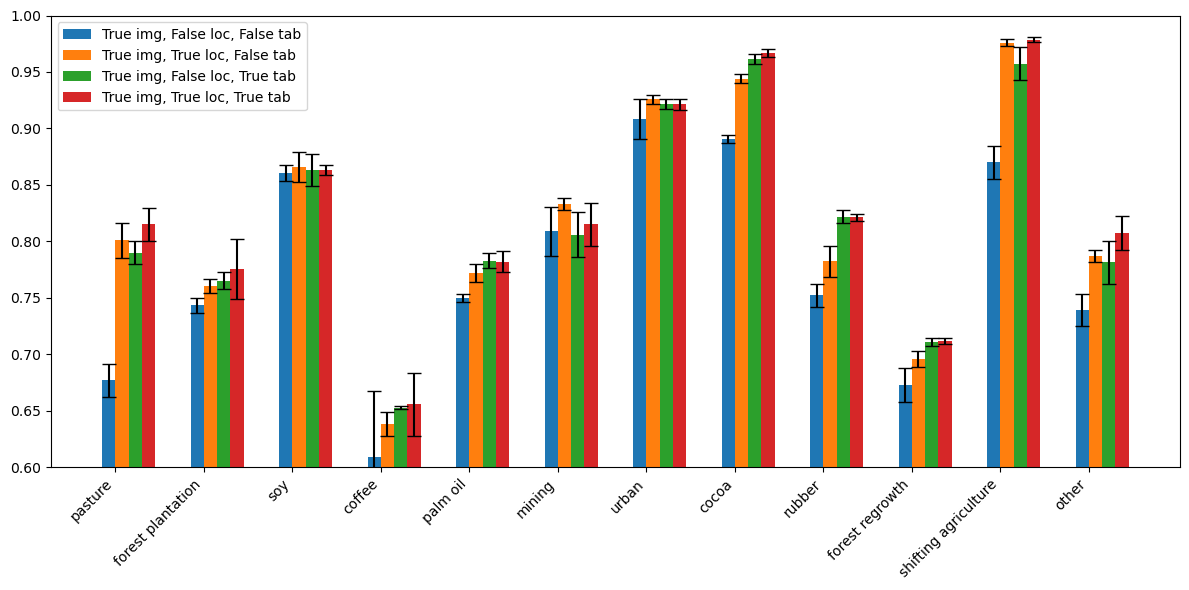

In [195]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(img_only_reordered): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.6)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

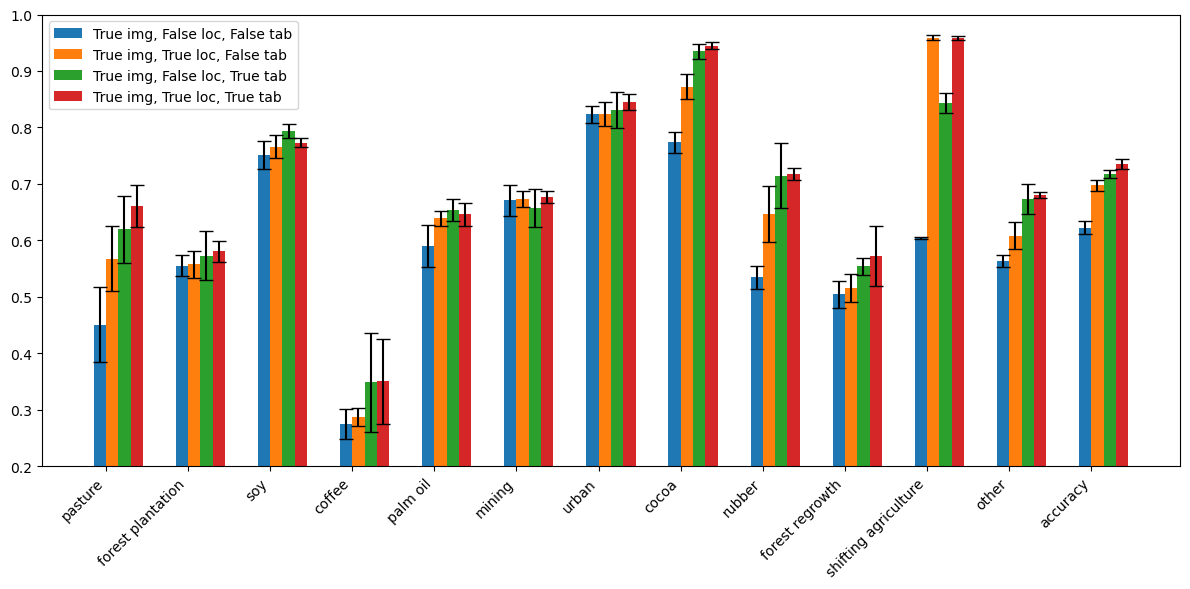

In [44]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(img_only_reordered): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.2)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

In [45]:
x = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/tabular/deduce_yearly.csv")

In [46]:
x.loc[x.country == 'Colombia'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,ColombiaColombiaColombiaColombiaColombiaColomb...,64.182842,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,ColombiaColombiaColombiaColombiaColombiaColomb...,1.939646,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",ColombiaColombiaColombiaColombiaColombiaColomb...,2.231461,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Bamboo),ColombiaColombiaColombiaColombiaColombiaColomb...,0.000110,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),ColombiaColombiaColombiaColombiaColombiaColomb...,3.981368,Forest plantationForest plantationForest plant...,44253
Leather,ColombiaColombiaColombiaColombiaColombiaColomb...,3.378044,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,ColombiaColombiaColombiaColombiaColombiaColomb...,0.687743,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,ColombiaColombiaColombiaColombiaColombiaColomb...,5.336640,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,ColombiaColombiaColombiaColombiaColombiaColomb...,0.442013,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [215]:
x.loc[x.country == 'Bolivia (Plurinational State of)'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,Bolivia (Plurinational State of)Bolivia (Pluri...,47.307818,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,Bolivia (Plurinational State of)Bolivia (Pluri...,0.095735,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",Bolivia (Plurinational State of)Bolivia (Pluri...,0.165045,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Unclassified),Bolivia (Plurinational State of)Bolivia (Pluri...,0.000029,Forest plantationForest plantationForest plant...,44253
Leather,Bolivia (Plurinational State of)Bolivia (Pluri...,2.489885,PasturePasturePasturePasturePasturePasturePast...,44253
Soya beans,Bolivia (Plurinational State of)Bolivia (Pluri...,16.963033,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [216]:
x.loc[x.country == 'Viet Nam'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,Viet NamViet NamViet NamViet NamViet NamViet N...,7.397770,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,Viet NamViet NamViet NamViet NamViet NamViet N...,0.206834,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",Viet NamViet NamViet NamViet NamViet NamViet N...,4.145469,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Australian Blackwood),Viet NamViet NamViet NamViet NamViet NamViet N...,0.000010,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),Viet NamViet NamViet NamViet NamViet NamViet N...,16.717140,Forest plantationForest plantationForest plant...,44253
Leather,Viet NamViet NamViet NamViet NamViet NamViet N...,0.389356,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,Viet NamViet NamViet NamViet NamViet NamViet N...,25.573644,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,Viet NamViet NamViet NamViet NamViet NamViet N...,0.001041,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,Viet NamViet NamViet NamViet NamViet NamViet N...,0.302824,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [224]:
x.loc[x.country == 'Brazil'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,75.068,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.348,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.400,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Birch),BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.000,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,1.963,Forest plantationForest plantationForest plant...,44253
Leather,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,3.951,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.095,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,0.033,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,BrazilBrazilBrazilBrazilBrazilBrazilBrazilBraz...,9.018,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [217]:
x.loc[x.country == 'Peru'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,51.613482,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,4.507773,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,6.456404,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Unclassified),PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,0.207253,Forest plantationForest plantationForest plant...,44253
Leather,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,2.716499,PasturePasturePasturePasturePasturePasturePast...,44253
Oil palm fruit,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,4.940126,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,PeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPeruPe...,0.021388,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [223]:
x.loc[x.country == 'Colombia'].groupby('Commodity').sum()

,country,commodity attributed deforestation,Commodity group,Year
Commodity,,,,
Cattle meat,ColombiaColombiaColombiaColombiaColombiaColomb...,64.183,PasturePasturePasturePasturePasturePasturePast...,44253
Cocoa beans,ColombiaColombiaColombiaColombiaColombiaColomb...,1.940,"Stimulant, spice and aromatic cropsStimulant, ...",44253
"Coffee, green",ColombiaColombiaColombiaColombiaColombiaColomb...,2.231,"Stimulant, spice and aromatic cropsStimulant, ...",44253
Forest plantation (Bamboo),ColombiaColombiaColombiaColombiaColombiaColomb...,0.000,Forest plantationForest plantationForest plant...,44253
Forest plantation (Unclassified),ColombiaColombiaColombiaColombiaColombiaColomb...,3.981,Forest plantationForest plantationForest plant...,44253
Leather,ColombiaColombiaColombiaColombiaColombiaColomb...,3.378,PasturePasturePasturePasturePasturePasturePast...,44253
Natural rubber in primary forms,ColombiaColombiaColombiaColombiaColombiaColomb...,0.688,Fibre cropsFibre cropsFibre cropsFibre cropsFi...,44253
Oil palm fruit,ColombiaColombiaColombiaColombiaColombiaColomb...,5.337,Oilseeds and oleaginous fruitsOilseeds and ole...,44253
Soya beans,ColombiaColombiaColombiaColombiaColombiaColomb...,0.442,Oilseeds and oleaginous fruitsOilseeds and ole...,44253


In [219]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)

### Part 2


- aggregate models across folds

In [10]:
model_names = []

for i, model_dict in enumerate(models):
    _name = "".join(model_dict['name'].split(';')[:-1])
    #if model_dict['wandb_id'] in failed.keys():
    #    print(_name)
    model_names.append(_name)
    
model_names = list(set(model_names))

In [11]:
model_names

['True img yes loc reports_token tabular',
 'True img no loc no tabular',
 'False img yes loc no tabular',
 'False img no loc reports_token tabular',
 'True img no loc reports_token tabular',
 'False img yes loc reports_token tabular',
 'True img yes loc no tabular']

In [12]:
agg_models = {}

for model_name in model_names:
    agg_models[model_name] = [model_dict for model_dict in models if "".join(model_dict['name'].split(';')[:-1]) == model_name]


In [13]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv")

In [14]:
for model_name, model_group in agg_models.items():
    
    labels[model_name] = None
    
    for model_dict in model_group:

        val_dst = int(model_dict['name'].split('[')[-1].split(']')[0])
        try:
            
            labels.loc[labels['split'] == val_dst, model_name] = [inverse_label_mapping[i] for i in model_dict['predictions']]
        except KeyError:
            print(model_name)
            continue
    

In [15]:
#Excluding test set, keepin train + val
train_test = labels.loc[labels.split != 4]

In [16]:
columns_with_only_none = train_test.columns[train_test.isnull().all()].tolist()

In [17]:
df_filtered = train_test.drop(columns=columns_with_only_none)

In [18]:
df_filtered.columns

Index(['geometry', 'driver', 'sampleid', 'dataset', 'split', 'country',
       'True img yes loc reports_token tabular', 'True img no loc no tabular',
       'False img yes loc no tabular',
       'False img no loc reports_token tabular',
       'True img no loc reports_token tabular',
       'False img yes loc reports_token tabular',
       'True img yes loc no tabular'],
      dtype='object')

In [19]:
from sklearn.metrics import classification_report

In [20]:
'''cols_with_model_results = ['yes loc  reports_token tab transformer cls',
       'yes loc  reports_raw tab fc cls', 'yes loc  reports_token tab fc cls',
       'no loc  no tab transformer cls',
       'no loc  reports_token tab transformer cls',
       'no loc  reports_raw tab fc cls', 'yes loc  no tab transformer cls',
       'yes loc  no tab fc cls', 'no loc  reports_token tab fc cls',
       'no loc  no tab fc cls']'''


cols_with_model_results = ['True img yes loc reports_token tabular', 'True img no loc no tabular',
       'False img yes loc no tabular',
       'False img no loc reports_token tabular',
       'True img no loc reports_token tabular',
       'False img yes loc reports_token tabular',
       'True img yes loc no tabular']



In [21]:
for col in cols_with_model_results:
    metrics = pd.DataFrame(classification_report(df_filtered['driver'], df_filtered[col], output_dict=True))
    print(col, '; accuracy:', metrics['accuracy']['f1-score'])


True img yes loc reports_token tabular ; accuracy: 0.8849441157133465
True img no loc no tabular ; accuracy: 0.8269514158108322
False img yes loc no tabular ; accuracy: 0.625042508331633


/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/jan/miniconda3/envs/torch/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1471: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


False img no loc reports_token tabular ; accuracy: 0.45337686186492554
True img no loc reports_token tabular ; accuracy: 0.8743793783581582
False img yes loc reports_token tabular ; accuracy: 0.6299848103561632
True img yes loc no tabular ; accuracy: 0.8807499603255572


In [164]:
#Filter examples where base model is incorrect and tri-modal model is correct

fixed = df_filtered.loc[
    (df_filtered['no loc  no tab transformer cls'] != df_filtered['driver'])
     & 
    (df_filtered['yes loc  reports_token tab transformer cls'] == df_filtered['driver'])
     ]

In [163]:
#Filter examples where base model is correct and tri-modal model is not

incorrect = df_filtered.loc[
    (df_filtered['no loc  no tab transformer cls'] == df_filtered['driver'])
     & 
    (df_filtered['yes loc  reports_token tab transformer cls'] != df_filtered['driver'])
     ]

In [177]:
classes, fixed_counts  = np.unique(fixed.driver, return_counts=True)

In [178]:
classes, incorrect_counts = np.unique(incorrect.driver, return_counts=True)

In [179]:
incorrect_counts

array([  4,  29, 228, 392, 250, 183, 296,  92, 164,  18, 188, 114])

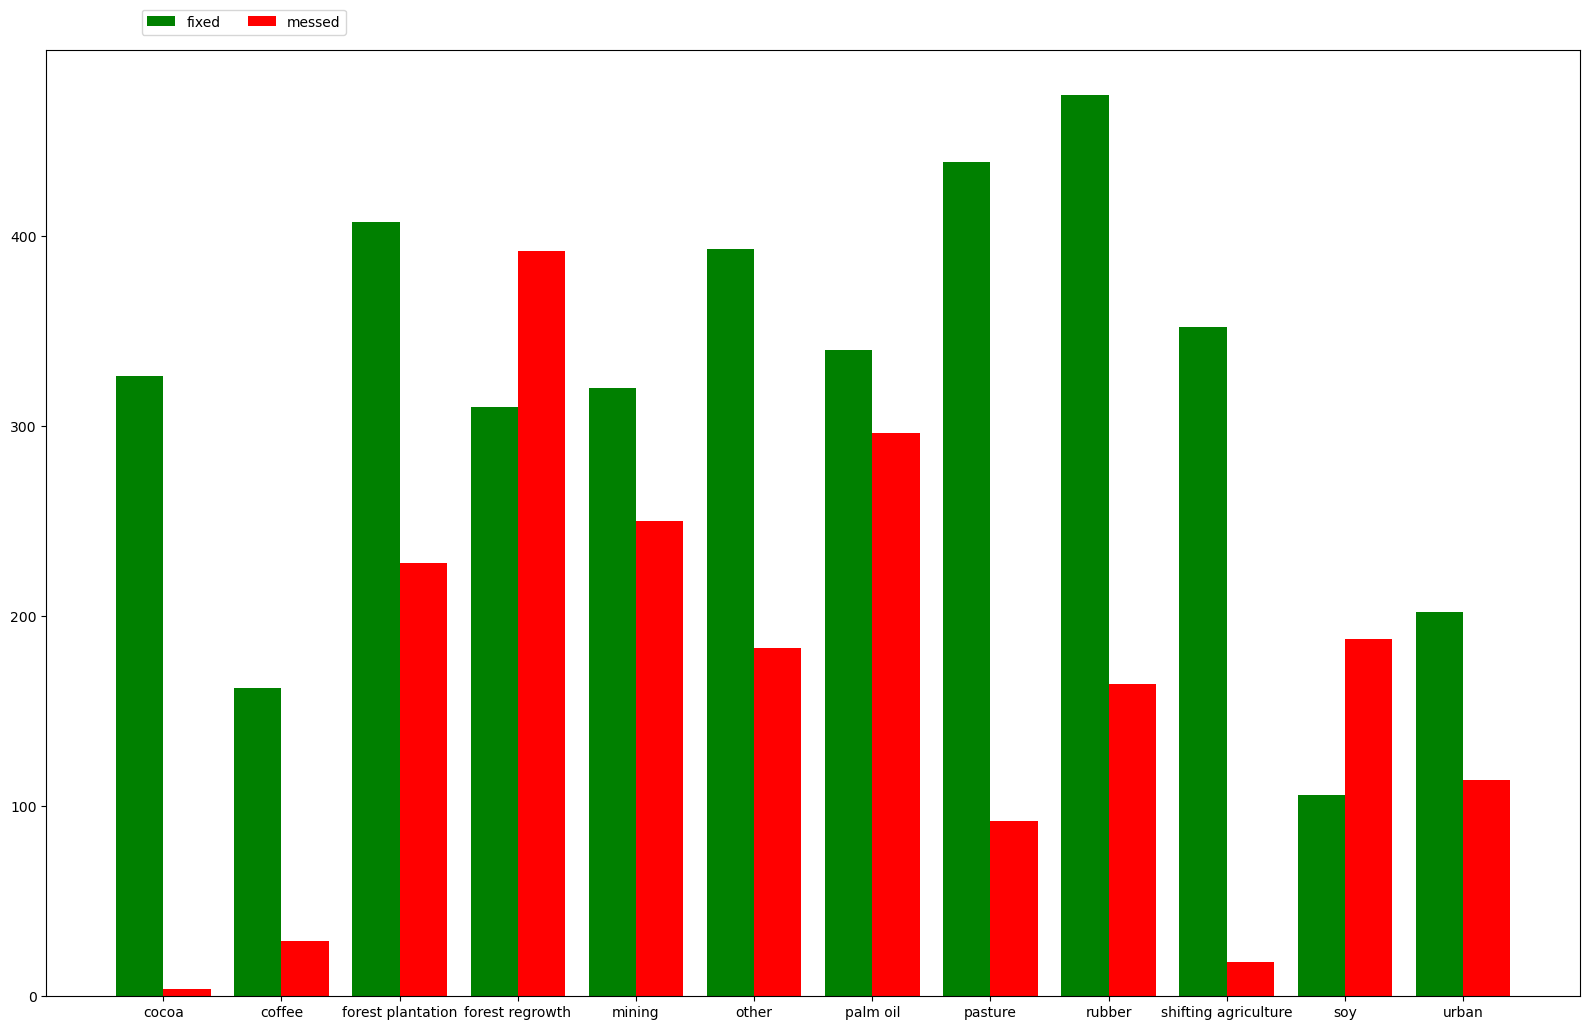

In [180]:

_x = np.arange(len(classes))  # the label locations
fig, ax = plt.subplots(1,figsize=(16,10))

ax.bar(_x-0.2, fixed_counts, width=0.4, color='green', align='center', label='fixed')
ax.bar(_x+0.2, incorrect_counts, width=0.4, color='red', align='center', label='messed')
plt.xticks(_x, classes) 
plt.tight_layout()
plt.legend(bbox_to_anchor=(0.2, 1.05), ncol=5)
plt.show()

In [182]:

cls, base_model_preds = np.unique(df_filtered['no loc  no tab transformer cls'], return_counts=True)
cls, trimodal_preds = np.unique(df_filtered['yes loc  reports_token tab transformer cls'], return_counts=True)

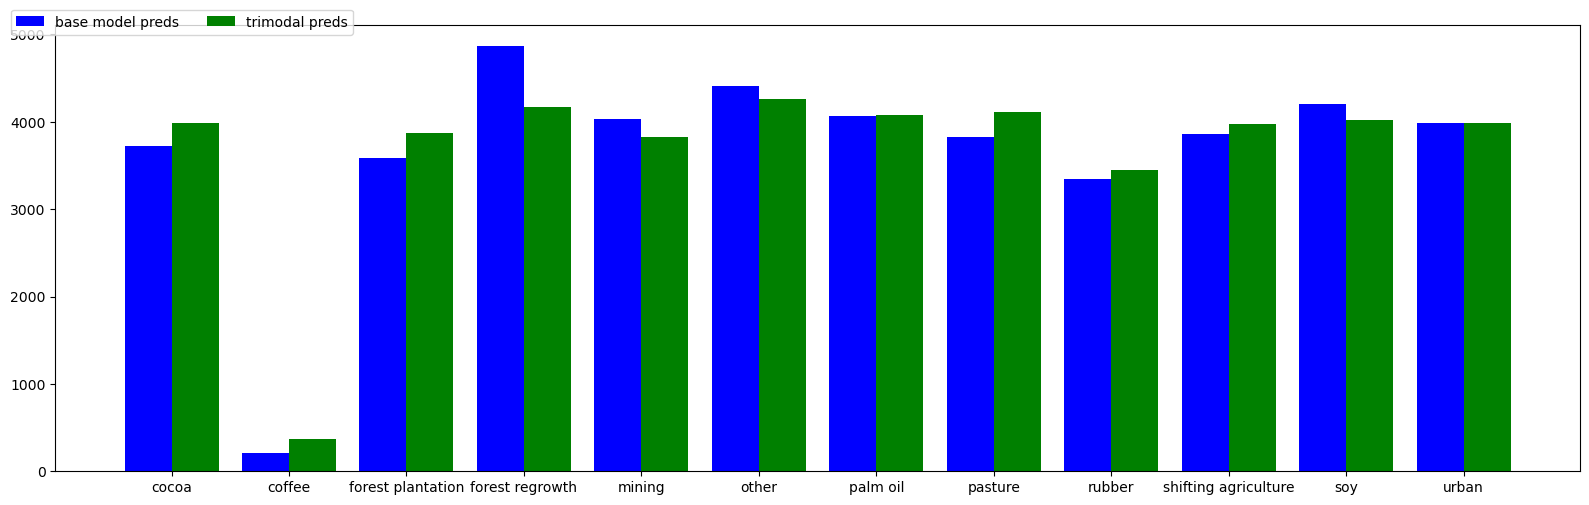

In [187]:

_x = np.arange(len(cls))  # the label locations
fig, ax = plt.subplots(1,figsize=(16,5))

ax.bar(_x-0.2, base_model_preds, width=0.4, color='blue', align='center', label='base model preds')
ax.bar(_x+0.2, trimodal_preds, width=0.4, color='green', align='center', label='trimodal preds')
plt.xticks(_x, classes) 
plt.tight_layout()
plt.legend(bbox_to_anchor=(0.2, 1.05), ncol=5)
plt.show()

In [198]:

    
incorrect_dict = dict(zip(*np.unique(incorrect.country, return_counts=True)))
fixed_dict = dict(zip(*np.unique(fixed.country, return_counts=True)))

In [201]:
for country in labels.country.unique():
    try:
        print(country)
        print('fixed: ',fixed_dict[country] , 'messed: ', incorrect_dict[country])
    except KeyError:
        continue

Ecuador
fixed:  245 messed:  25
Côte d'Ivoire
fixed:  21 messed:  2
Ghana
fixed:  77 messed:  57
Colombia
fixed:  26 messed:  13
Brazil
fixed:  1011 messed:  655
Viet Nam
fixed:  230 messed:  42
Indonesia
fixed:  1133 messed:  890
Malaysia
fixed:  101 messed:  69
Mexico
fixed:  13 messed:  2
Cuba
fixed:  11 messed:  7
Bolivia (Plurinational State of)
fixed:  5 messed:  2
United States of America
Australia
fixed:  3 messed:  3
Guatemala
fixed:  3 messed:  3
Philippines
fixed:  15 messed:  2
Lao People's Democratic Republic
fixed:  45 messed:  23
Peru
fixed:  56 messed:  1
Guyana
fixed:  18 messed:  3
India
fixed:  5 messed:  1
Democratic Republic of the Congo
fixed:  255 messed:  42
Papua New Guinea
fixed:  13 messed:  7
Gabon
fixed:  24 messed:  4
Uganda
fixed:  6 messed:  3
Venezuela (Bolivarian Republic of)
fixed:  14 messed:  3
Sri Lanka
Myanmar
fixed:  33 messed:  32
Suriname
Ethiopia
fixed:  2 messed:  1
Liberia
fixed:  8 messed:  1
Thailand
fixed:  178 messed:  18
Bahamas
Kenya
f

In [23]:

df_filtered

,geometry,driver,sampleid,dataset,split,country,True img yes loc reports_token tabular,True img no loc no tabular,False img yes loc no tabular,False img no loc reports_token tabular,True img no loc reports_token tabular,False img yes loc reports_token tabular,True img yes loc no tabular
1,POINT (-3.252726923505843 6.05540773743447),cocoa,30005848,cocoa.csv,1,Côte d'Ivoire,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
2,POINT (-1.8324904593128795 6.046244921563979),cocoa,30005875,cocoa.csv,1,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
6,POINT (-0.7054641038565277 5.624755391523431),cocoa,30007242,cocoa.csv,0,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
7,POINT (-79.5647662448441 -1.9379355564808602),cocoa,110003683,cocoa_ecuador.csv,0,Ecuador,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
9,POINT (-0.6413243925703949 6.412757556385085),cocoa,30004120,cocoa.csv,2,Ghana,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa,cocoa
...,...,...,...,...,...,...,...,...,...,...,...,...,...
55298,POINT (76.66305108549047 10.758438413532348),urban,100002981,worldcover.csv,1,India,urban,urban,urban,urban,urban,urban,urban
55299,POINT (106.68137671728651 -6.334442760971974),urban,100009782,worldcover.csv,1,Indonesia,urban,urban,other,other,urban,other,urban
55300,POINT (-35.322382484061244 -5.749666958458276),urban,10427227,mapbiomas.csv,2,Brazil,urban,urban,urban,pasture,urban,pasture,urban
55301,POINT (101.5439344788162 3.154945653990399),urban,100004466,worldcover.csv,1,Malaysia,urban,urban,urban,urban,urban,urban,urban


## Plot and check examples of (i) where the tri-modal helped and (ii) where it made it worse

In [24]:
df_filtered['True img yes loc reports_token tabular'] 

1        cocoa
2        cocoa
6        cocoa
7        cocoa
9        cocoa
         ...  
55298    urban
55299    urban
55300    urban
55301    urban
55302    urban
Name: True img yes loc reports_token tabular, Length: 44109, dtype: object

In [25]:

incorrect = df_filtered.loc[

    (df_filtered['True img yes loc reports_token tabular'] != df_filtered['driver'])
     ]

In [28]:
np.unique(incorrect['driver'], return_counts=True)

(array(['cocoa', 'coffee', 'forest plantation', 'forest regrowth',
        'mining', 'other', 'palm oil', 'pasture', 'rubber',
        'shifting agriculture', 'soy', 'urban'], dtype=object),
 array([ 24, 114, 819, 887, 560, 628, 734, 362, 494,  45, 215, 193]))